In [18]:
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from sboxes.loader import load as load_sbox
from evaluation.uniformity import ddt
from evaluation.avalanche_criterion import print_avalanche_summary, plot_avalanche_matrix
from evaluation.markov_chains.basic_markov_chain import DifferentialMarkovChain

from evaluation.markov_chains.basic_markov_chain import create_transition_matrix, create_transition_matrix_from_sbox

In [19]:
def test_sbox_markov(sbox, epsilon=1e-4, r_values=[1,2,5,10]):
    """
    Ejecuta pruebas de Markov en la S-Box:
     - Doble estocasticidad, irreducibilidad, aperiodicidad, ergodicidad
     - Mixing times iterativo y espectral
     - TV distance y max probability
     - Gráfica TV distance vs pasos
    """
    print(f"\n### Pruebas MarkovChain para {type(sbox).__name__}")
    P = create_transition_matrix_from_sbox(sbox)
    chain = DifferentialMarkovChain(P)

    # Propiedades
    print("Doble estocástica:", chain.is_doubly_stochastic())
    print("Irreducible:", chain.is_irreducible())
    print("Aperiodic:", chain.is_aperiodic())
    print("Ergódica:", chain.is_ergodic())

    # Mixing times
    tau_iter = chain.mixing_time_iterative(epsilon)
    tau_spec = chain.mixing_time_spectral(epsilon)
    print(f"Mixing time iterativo (ε={epsilon}): {tau_iter}")
    print(f"Mixing time espectral  (ε={epsilon}): {tau_spec}")

    # TV distance y max probability
    for r in r_values:
        tv = chain.tv_distance(r)
        mp = chain.max_probability(r)
        print(f"Paso {r}: TV_distance={tv:.6f}, max_probability={mp:.6f}")

    # Gráfica TV distance vs r
    rs = list(range(1, max(r_values)+1))
    tvs = [chain.tv_distance(r) for r in rs]
    plt.figure(figsize=(6,4))
    plt.plot(rs, tvs, marker='o')
    plt.title(f"TV Distance vs Steps: {type(sbox).__name__}")
    plt.xlabel("Steps r")
    plt.ylabel("TV Distance")
    plt.grid(True)
    plt.show()

In [20]:
# Cargar ASCON S-Box
ascon = load_sbox('sboxes/data/ascon.json')
print('# S-Box ASCON')

# S-Box ASCON


## 1. Avalanche Criterion
SAC promedio general: 0.620
Desviación estándar máxima: 0.374
╒═════╤═══════════╤═══════════╕
│     │   Avg SAC │   Std SAC │
╞═════╪═══════════╪═══════════╡
│ In0 │       0.6 │     0.2   │
├─────┼───────────┼───────────┤
│ In1 │       0.7 │     0.245 │
├─────┼───────────┼───────────┤
│ In2 │       0.6 │     0.374 │
├─────┼───────────┼───────────┤
│ In3 │       0.7 │     0.245 │
├─────┼───────────┼───────────┤
│ In4 │       0.5 │     0.316 │
╘═════╧═══════════╧═══════════╛


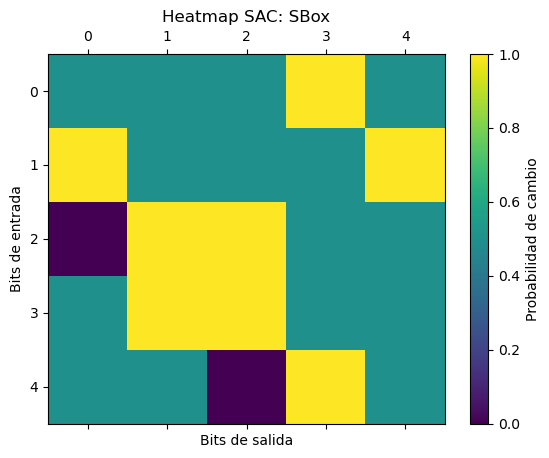

In [21]:
# 1. Avalanche Criterion
print('## 1. Avalanche Criterion')
print_avalanche_summary(ascon)
plot_avalanche_matrix(ascon)

## 2. Pruebas de la Cadena de Markov

### Pruebas MarkovChain para SBox
Doble estocástica: True
Irreducible: True
Aperiodic: True
Ergódica: True
Mixing time iterativo (ε=0.0001): 11
Mixing time espectral  (ε=0.0001): 14
Paso 1: TV_distance=0.870968, max_probability=0.250000
Paso 2: TV_distance=0.429435, max_probability=0.109375
Paso 5: TV_distance=0.018941, max_probability=0.035126
Paso 10: TV_distance=0.000116, max_probability=0.032278


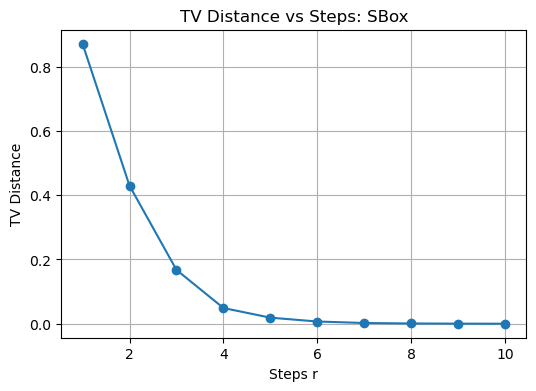

In [22]:
# 2. Pruebas de Cadena de Markov
print('## 2. Pruebas de la Cadena de Markov')
test_sbox_markov(ascon)

# Measures

In [23]:

from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox
from evaluation.markov_chains.all_test_markov_chains import (
    compare_tv_distance,
    compare_max_probability,
    compare_mixing_times
)
TABLEAU10 = [
  "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
  "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"
]

TABLEAU10 = ["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#ffff33","#a65628","#f781bf","#999999"]
"""
["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#ffff33","#a65628","#f781bf","#999999"]
["#a6cee3","#1f78b4","#b2df8a","#33a02c","#fb9a99","#e31a1c","#fdbf6f","#ff7f00","#cab2d6","#6a3d9a","#ffff99","#b15928"]

cmap = plt.cm.Set1        # o 'tab10', 'Paired', 'viridis', etc.
colors = cmap.colors      # para colormaps discretos (Set1, tab10)
# o, para continuos:
color_mid   = plt.cm.viridis(0.5)

"""

'\n["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#ffff33","#a65628","#f781bf","#999999"]\n["#a6cee3","#1f78b4","#b2df8a","#33a02c","#fb9a99","#e31a1c","#fdbf6f","#ff7f00","#cab2d6","#6a3d9a","#ffff99","#b15928"]\n\ncmap = plt.cm.Set1        # o \'tab10\', \'Paired\', \'viridis\', etc.\ncolors = cmap.colors      # para colormaps discretos (Set1, tab10)\n# o, para continuos:\ncolor_mid   = plt.cm.viridis(0.5)\n\n'

In [24]:
to_proof = ["aes", "07_Romulus"]#"nuestro 5.v1", "nuestro 5.v2", "nuestro 5.v3"]
identidad = IdentitySBox(5)
#nuestra5_nuevo = load_sbox("sboxes/data/nuestro 5.2.json")
specs = []

for sbox_link in to_proof:
    sbox = load_sbox(f"sboxes/data/{sbox_link}.json")
    specs.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': TABLEAU10[len(specs) % len(TABLEAU10)],
        'sbox': sbox
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: AES (8x8)
Procesando S-Box: Romulus/Skinny-128-384+ (8x8)


In [25]:
import json
from sboxes import SBox

# ---------- 1. Cargar el JSON ----------
with open("results/8x8/data.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# ---------- 2. Procesar cada S-Box ----------
for idx, sb in enumerate(data["sboxes"]):
 
    print(sb)        
    table = list(map(lambda x: hex(x), sb["table"]))                   # lista de enteros
    n_in  = int(np.log2(len(table)))            # nº de bits de entrada
    n_out = int(np.ceil(np.log2(max(sb["table"])+1)))  # nº de bits de salida
    name = f"Variant #{idx}"
    biggest_possible_output = 1 << n_out
    final_table = np.empty(len(table), dtype=np.uint64)
    for idx, i in enumerate(table):#sb["table"]):
        output = int(i, 0)
        if output > biggest_possible_output or output < 0:
            raise ValueError("Table values must be greater than or equal to 0 and less than or equal to 2^%d" % n_out)
        final_table[idx] = output
        
    sbox = SBox(n_in, n_out, final_table, name)                      # <- ajusta a tu clase
    print("size:",len(sb["table"]))
    specs.append({
        "name": name,              # pon aquí el nombre que prefieras
        "table": sbox.table.tolist(),
        "n_in": n_in,
        "n_out": n_out,
        "color": TABLEAU10[len(specs) % len(TABLEAU10)],
        "sbox":  sbox
    })

# ---------- 3. (Opcional) comprobar ----------
print(f"{len(specs)} S-Boxes cargadas desde data.json")
for s in specs:
    print(s["name"], "–", s["n_in"], "→", s["n_out"])

{'cost': 0.29492525181975804, 'linearity': 102.0, 'uniformity': 8.0, 'table': [251, 205, 169, 154, 20, 227, 77, 133, 97, 202, 99, 97, 17, 250, 134, 181, 251, 196, 230, 191, 185, 32, 229, 202, 3, 231, 240, 74, 168, 230, 124, 30, 160, 115, 3, 238, 181, 58, 51, 186, 208, 56, 6, 31, 1, 113, 79, 135, 151, 192, 164, 3, 144, 126, 18, 24, 186, 70, 234, 42, 27, 224, 149, 94, 196, 70, 86, 75, 232, 228, 219, 115, 43, 11, 128, 223, 45, 197, 92, 2, 155, 23, 213, 141, 180, 10, 180, 117, 148, 120, 245, 158, 20, 69, 128, 50, 211, 239, 84, 94, 95, 159, 93, 191, 58, 0, 217, 136, 246, 171, 242, 194, 1, 192, 235, 226, 59, 22, 61, 147, 217, 118, 147, 42, 7, 162, 210, 159, 1, 162, 70, 118, 160, 158, 61, 67, 41, 86, 101, 132, 36, 126, 53, 195, 175, 104, 55, 64, 69, 200, 207, 159, 81, 220, 227, 161, 35, 102, 42, 177, 52, 215, 184, 22, 56, 161, 167, 150, 243, 184, 173, 8, 67, 7, 193, 83, 200, 224, 106, 13, 34, 183, 39, 51, 31, 221, 183, 23, 254, 229, 41, 172, 218, 181, 193, 59, 187, 243, 92, 100, 193, 67, 123,

In [26]:
for elem in specs:
    
    chain = DifferentialMarkovChain(create_transition_matrix_from_sbox(elem['sbox']))
    print(f"-- {elem['name']} --")
    print("Doble estocástica:", chain.is_doubly_stochastic())
    print("Irreducible:", chain.is_irreducible())
    print("Aperiodic:", chain.is_aperiodic())
    print("Ergódica:", chain.is_ergodic())
    print("\n")

-- AES --
Doble estocástica: True
Irreducible: True
Aperiodic: True
Ergódica: True


-- Romulus/Skinny-128-384+ --
Doble estocástica: True
Irreducible: True
Aperiodic: True
Ergódica: True


-- Variant #0 --
Doble estocástica: False
Irreducible: False


LinAlgError: Last 2 dimensions of the array must be square

|   r |    ASCON |   FIDES_5 |   Variant #0 |   Variant #1 |   Variant #2 |   Variant #3 |   Variant #4 |   Variant #5 |   Variant #6 |   Variant #7 |   Variant #8 |
|-----|----------|-----------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|
|   1 | 0.870968 |  0.483871 |     0.613216 |     0.629918 |     0.628319 |     0.609522 |     0.600276 |     0.615219 |     0.615076 |     0.614927 |     0.640185 |
|   2 | 0.429435 |  0.068044 |     0.14863  |     0.130506 |     0.134972 |     0.134704 |     0.132232 |     0.144578 |     0.135503 |     0.118259 |     0.144248 |
|   3 | 0.167465 |  0.011435 |     0.035033 |     0.024117 |     0.027059 |     0.033036 |     0.029677 |     0.03097  |     0.030047 |     0.025598 |     0.031311 |
|   4 | 0.048938 |  0.002276 |     0.007001 |     0.004967 |     0.006213 |     0.00672  |     0.006295 |     0.00696  |     0.006876 |     0.004967 |     0.007068 |
|   

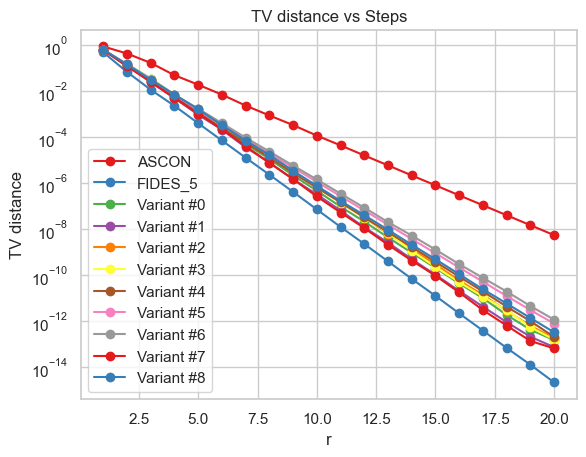

In [ ]:
 # Comparaciones
ans = compare_tv_distance(specs, detail=True, graphic=True, log_scale=1)

|   r |    ASCON |   FIDES_5 |   Variant #0 |   Variant #1 |   Variant #2 |   Variant #3 |   Variant #4 |   Variant #5 |   Variant #6 |   Variant #7 |   Variant #8 |
|-----|----------|-----------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|
|   1 | 0.25     |  0.0625   |     0.142857 |     0.142857 |     0.142857 |     0.142857 |     0.133333 |     0.133333 |     0.133333 |     0.142857 |     0.142857 |
|   2 | 0.109375 |  0.039062 |     0.065179 |     0.067474 |     0.064206 |     0.064323 |     0.06849  |     0.063542 |     0.067448 |     0.061825 |     0.059933 |
|   3 | 0.056641 |  0.035156 |     0.048162 |     0.050981 |     0.04847  |     0.048843 |     0.054139 |     0.047536 |     0.045355 |     0.049779 |     0.042716 |
|   4 | 0.041748 |  0.032715 |     0.04504  |     0.047547 |     0.046522 |     0.046618 |     0.049039 |     0.0445   |     0.043132 |     0.047009 |     0.039351 |
|   

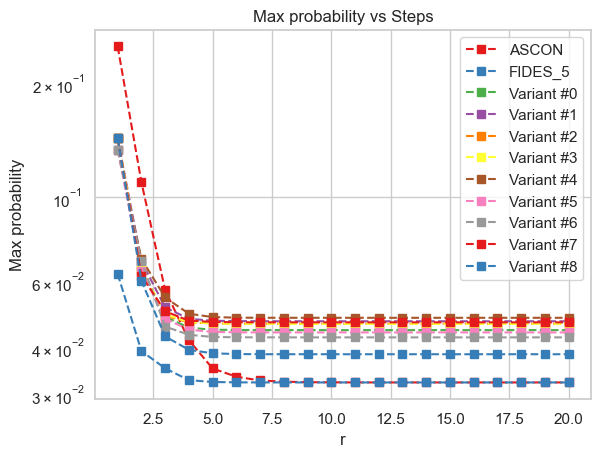

In [ ]:
ans = compare_max_probability(specs, detail=True, graphic=True, log_scale=True)


|      ε |   ASCON iter |   FIDES_5 iter |   Variant #0 iter |   Variant #1 iter |   Variant #2 iter |   Variant #3 iter |   Variant #4 iter |   Variant #5 iter |   Variant #6 iter |   Variant #7 iter |   Variant #8 iter |   ASCON spec |   FIDES_5 spec |   Variant #0 spec |   Variant #1 spec |   Variant #2 spec |   Variant #3 spec |   Variant #4 spec |   Variant #5 spec |   Variant #6 spec |   Variant #7 spec |   Variant #8 spec |
|--------|--------------|----------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|--------------|----------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|
| 0.1    |            4 |              2 |                 3 |                 3 |                 3 |                 3 |        

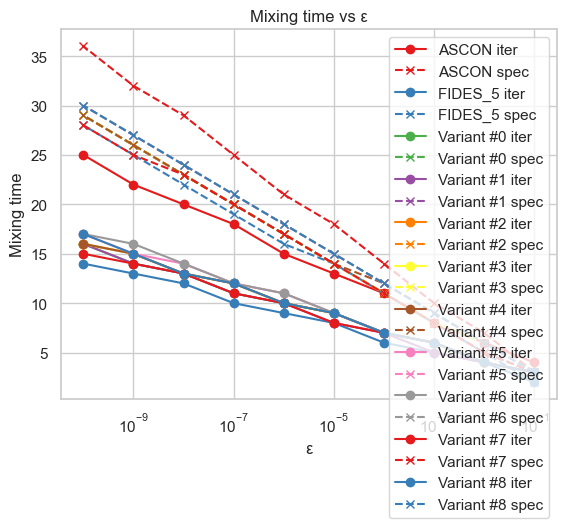

In [ ]:
ans = compare_mixing_times(specs, detail=True, graphic=True, log_scale=True)    

## pruebas librerias

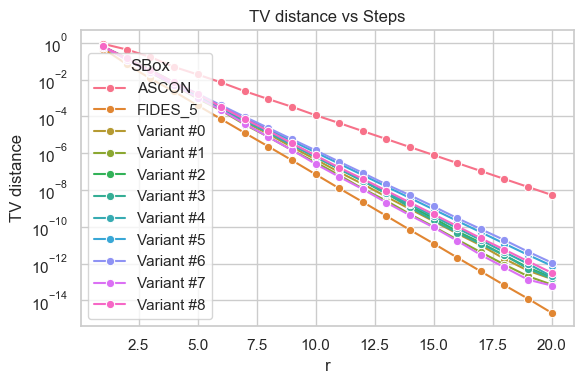

In [ ]:
from evaluation.markov_chains.all_test_markov_chains import (
    compare_with_altair,
    compare_with_seaborn,
    compare_with_plotnine
)
compare_with_seaborn(specs, log_scale=1) 

In [ ]:
compare_with_altair(specs, log_scale=1)  

c:\ProgramData\anaconda3\Lib\site-packages\altair\utils\core.py:395: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
c:\ProgramData\anaconda3\Lib\site-packages\altair\utils\core.py:395: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.


alt.Chart(...)

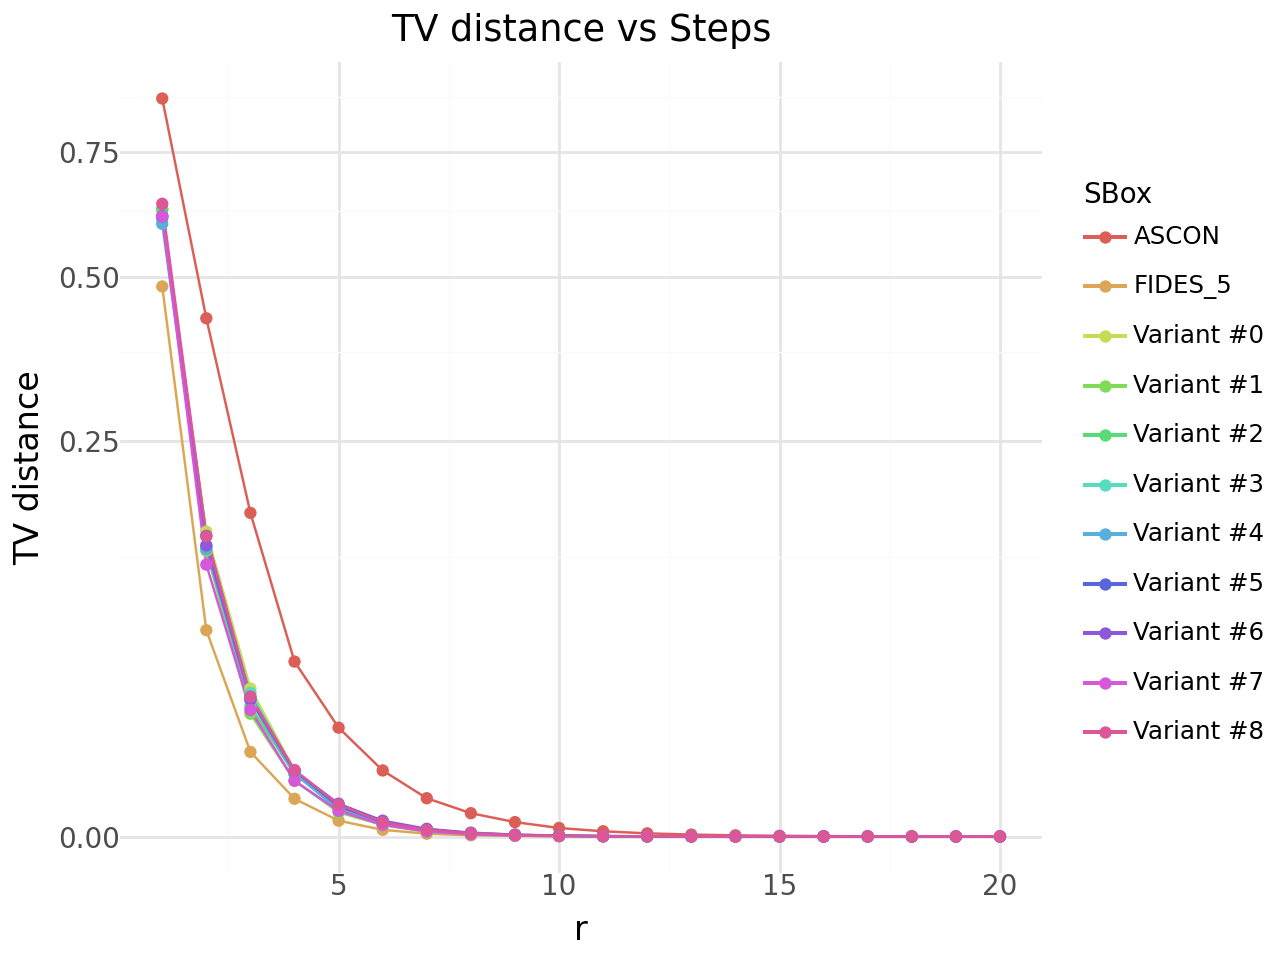

In [ ]:
compare_with_plotnine(specs, log_scale=2) 

In [ ]:
def compare_tv_distance(specs, detail: bool = False, graphic: bool = False, log_scale: bool = False, r_values=None, ):
    """
    Compara TV distance para varias S-Boxes.
    specs: lista de dicts {'name', 'table', 'n_in', 'n_out', 'color'}
    """
    if r_values is None:
        r_values = list(range(1, 21))
    # Crear cadenas
    chains = {
        spec['name']: (DifferentialMarkovChain(
                          create_transition_matrix(
                            np.array(spec['table']),
                            spec['n_in'], spec['n_out']
                          )),
                        spec['color'])
        for spec in specs
    }

    # Mostrar tabla
    headers = ['r'] + list(chains.keys())
    rows = []
    for r in r_values:
        row = [r] + [f"{chains[name][0].tv_distance(r):.6f}" for name in chains]
        rows.append(row)
    if detail:
        print(tabulate(rows, headers=headers, tablefmt="github"))

    # Graficar
    if graphic:
        plt.figure()
        for name, (chain, color) in chains.items():
            tvs = [chain.tv_distance(r) for r in r_values]
            plt.plot(r_values, tvs, 'o-', label=name, color=color)
        plt.xlabel('r')
        plt.ylabel('TV distance')
        if log_scale == 1:
            plt.yscale('log')
        elif log_scale == 2:
            plt.yscale('logit')
        plt.title('TV distance vs Steps')
        plt.legend()
        plt.grid(True)
        plt.show()
    return {name: [chain.tv_distance(r) for r in r_values] for name, (chain, _) in chains.items()}


# Clasicas

0 -> 4
1 -> 11
2 -> 31
3 -> 20
4 -> 26
5 -> 21
6 -> 9
7 -> 2
8 -> 27
9 -> 5
10 -> 8
11 -> 18
12 -> 29
13 -> 3
14 -> 6
15 -> 28
16 -> 30
17 -> 19
18 -> 7
19 -> 14
20 -> 0
21 -> 13
22 -> 17
23 -> 24
24 -> 16
25 -> 12
26 -> 1
27 -> 25
28 -> 22
29 -> 10
30 -> 15
31 -> 23
0 -> 1
1 -> 0
2 -> 25
3 -> 26
4 -> 17
5 -> 29
6 -> 21
7 -> 27
8 -> 20
9 -> 5
10 -> 4
11 -> 23
12 -> 14
13 -> 18
14 -> 2
15 -> 28
16 -> 15
17 -> 8
18 -> 6
19 -> 3
20 -> 13
21 -> 7
22 -> 24
23 -> 16
24 -> 30
25 -> 9
26 -> 31
27 -> 10
28 -> 22
29 -> 12
30 -> 11
31 -> 19
0 -> 7
1 -> 21
2 -> 10
3 -> 6
4 -> 24
5 -> 3
6 -> 15
7 -> 11
8 -> 12
9 -> 14
10 -> 8
11 -> 18
12 -> 20
13 -> 9
14 -> 14
15 -> 20
16 -> 10
17 -> 25
18 -> 11
19 -> 15
20 -> 7
21 -> 24
22 -> 5
23 -> 22
24 -> 19
25 -> 5
26 -> 13
27 -> 7
28 -> 0
29 -> 7
30 -> 16
31 -> 14
32 -> 5
33 -> 20
34 -> 20
35 -> 5
36 -> 0
37 -> 7
38 -> 12
39 -> 5
40 -> 0
41 -> 0
42 -> 7
43 -> 7
44 -> 0
45 -> 0
46 -> 0
47 -> 5
48 -> 5
49 -> 31
50 -> 19
51 -> 18
52 -> 7
53 -> 26
54 -> 16
55 ->

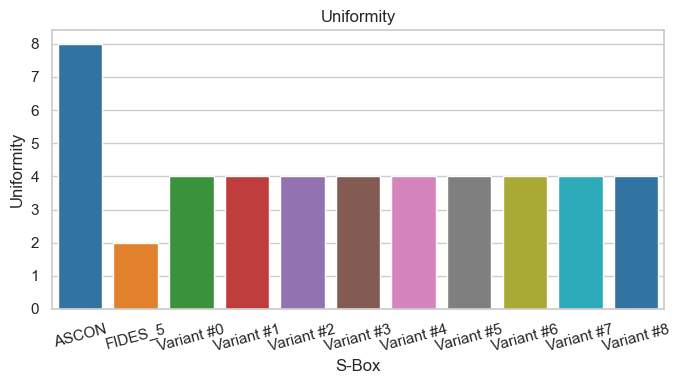

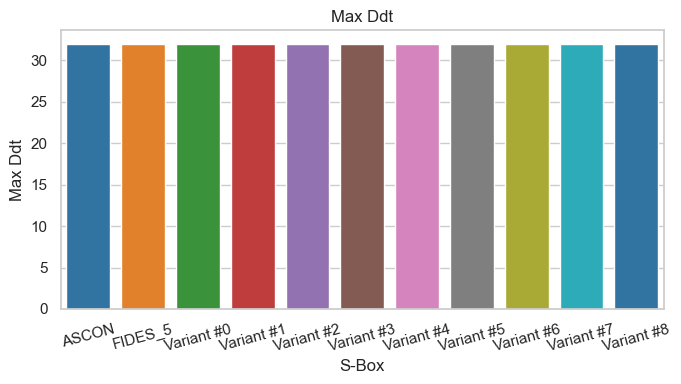

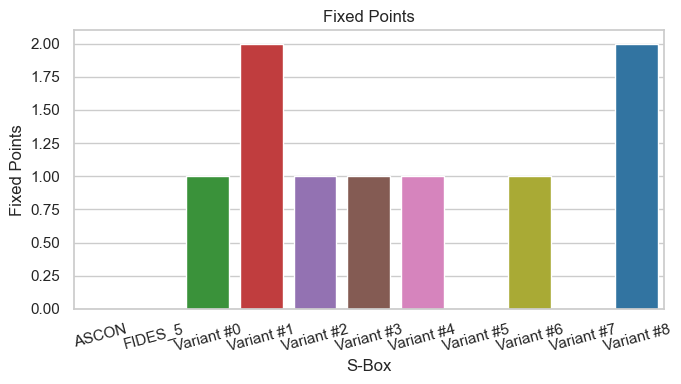

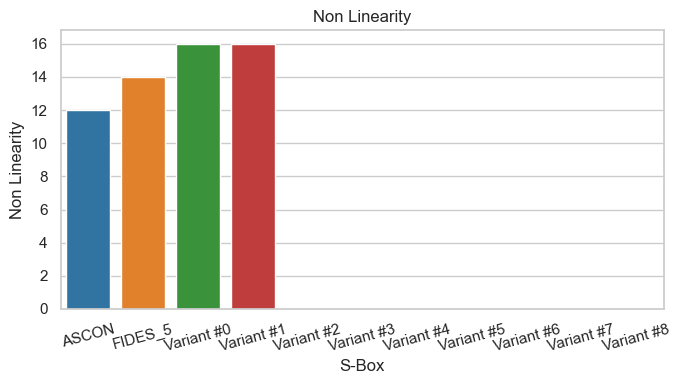

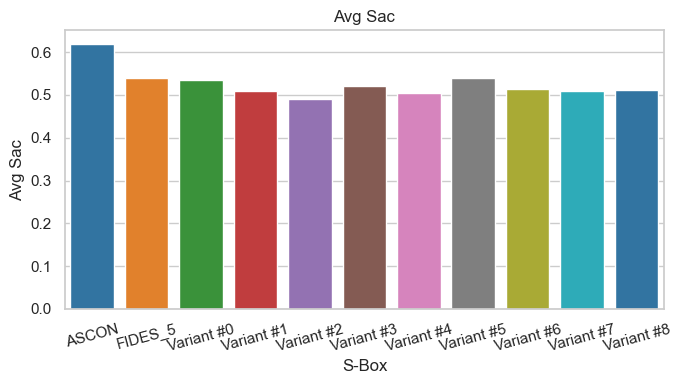

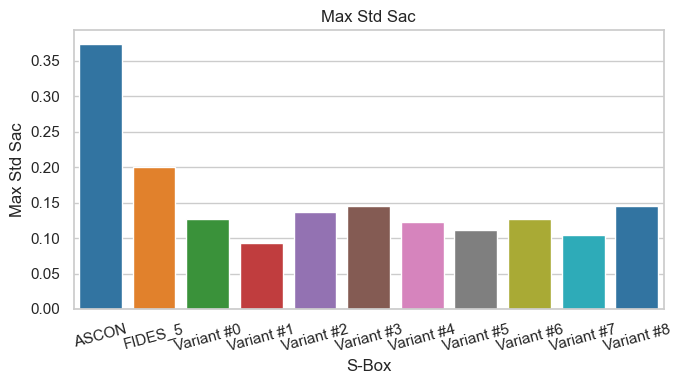

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,ASCON,8,32,0,12.0,0.6200,0.374166
1,FIDES_5,2,32,0,14.0,0.5400,0.200000
2,Variant #0,4,32,1,16.0,0.5350,0.127475
3,Variant #1,4,32,2,16.0,0.5100,0.093541
4,Variant #2,4,32,1,NaN,0.4900,0.136931
5,Variant #3,4,32,1,NaN,0.5200,0.145774
6,Variant #4,4,32,1,NaN,0.5050,0.122474
7,Variant #5,4,32,0,NaN,0.5400,0.111803
8,Variant #6,4,32,1,NaN,0.5150,0.127475
9,Variant #7,4,32,0,NaN,0.5100,0.104583


In [ ]:
from evaluation.sbox_metrics_analysis import run_all_metrics

# Define specs (como ya haces) y tus valores de no-linealidad:
non_linearities = [12, 14, 16, 16]  # valores que tú determines
run_all_metrics(specs, non_linearities)

In [ ]:

from evaluation.markov_chains.basic_markov_chain import create_transition_matrix  # tu función
import numpy as np

import pandas as pd
from neurokit2 import markov_mixingtime

def compute_neurokit_mixing_time(sbox_table, n_in, n_out):
    P = create_transition_matrix(np.array(sbox_table), n_in, n_out)
    assert np.allclose(P.sum(axis=1), 1), "Matriz de transición inválida"

    # Crear índice y columnas etiquetadas para DataFrame
    states = [f"{i}" for i in range(P.shape[0])]
    tm = pd.DataFrame(P, index=states, columns=states)

    tau = markov_mixingtime(tm)
    return tau


for spec in specs:
    tau = compute_neurokit_mixing_time(spec['table'], spec['n_in'], spec['n_out'])
    print(f"{spec['name']}: Mixing time (NeuroKit) = {tau:.4f}")


ASCON: Mixing time (NeuroKit) = 1.5844
FIDES_5: Mixing time (NeuroKit) = 1.2147
Variant #0: Mixing time (NeuroKit) = 1.2332
Variant #1: Mixing time (NeuroKit) = 1.2567
Variant #2: Mixing time (NeuroKit) = 1.2277
Variant #3: Mixing time (NeuroKit) = 1.1999
Variant #4: Mixing time (NeuroKit) = 1.2226
Variant #5: Mixing time (NeuroKit) = 1.3154
Variant #6: Mixing time (NeuroKit) = 1.2529
Variant #7: Mixing time (NeuroKit) = 1.2012
Variant #8: Mixing time (NeuroKit) = 1.2275
